In [19]:
# ============================================================
# IMPORTS AND CONFIGURATION
# ============================================================

import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.model_selection import ParameterGrid
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
MAX_TUNING_SAMPLES = 6000
MAX_FINAL_SVR_SAMPLES = 8000
PROJECT_DIR = Path.cwd()
if not (PROJECT_DIR / "data").exists() and (PROJECT_DIR.parent / "data").exists():
    PROJECT_DIR = PROJECT_DIR.parent
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "nox_svr"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


In [20]:
# ============================================================
# LOAD AND PREPARE DATA
# ============================================================

files = sorted(DATA_DIR.glob("gt_*.csv"))
if not files:
    raise FileNotFoundError(f"No gt_*.csv files found in {DATA_DIR.resolve()}")
frames = []
for file in files:
    frame = pd.read_csv(file)
    frame["Year"] = int(file.stem.split("_")[-1])
    frames.append(frame)
data = pd.concat(frames, ignore_index=True)
feature_cols = ["AT", "AP", "AH", "AFDP", "GTEP", "TIT", "TAT", "CDP"]
required_cols = feature_cols + ["NOX", "Year"]
missing_cols = [col for col in required_cols if col not in data.columns]
if missing_cols:
    raise ValueError(f"Missing columns: {missing_cols}")
data = data.dropna(subset=required_cols).reset_index(drop=True)
train_data = data[data["Year"] <= 2014].copy().reset_index(drop=True)
test_data = data[data["Year"] == 2015].copy().reset_index(drop=True)
X_train = train_data[feature_cols]
X_test = test_data[feature_cols]
y_train = train_data["NOX"]
y_test = test_data["NOX"]
if train_data.empty or test_data.empty:
    raise ValueError("Both 2011–2014 development data and 2015 comparison data are required.")
print("Development observations:", len(train_data))
print("2015 comparison observations:", len(test_data))


Development observations: 29349
2015 comparison observations: 7384


In [21]:
# ============================================================
# DEFINE EVALUATION FUNCTION
# ============================================================

def calculate_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }


In [22]:
# ============================================================
# CHRONOLOGICAL TRAINING AND VALIDATION SPLIT
# ============================================================

fit_data = train_data[train_data["Year"] <= 2013].copy().reset_index(drop=True)
validation_data = train_data[train_data["Year"] == 2014].copy().reset_index(drop=True)

def evenly_spaced_sample(frame, max_samples):
    if len(frame) <= max_samples:
        return frame.copy().reset_index(drop=True)
    positions = np.linspace(0, len(frame) - 1, max_samples, dtype=int)
    return frame.iloc[positions].copy().reset_index(drop=True)

tuning_data = evenly_spaced_sample(fit_data, MAX_TUNING_SAMPLES)
X_fit = tuning_data[feature_cols]
y_fit = tuning_data["NOX"]
X_validation = validation_data[feature_cols]
y_validation = validation_data["NOX"]

print("SVR tuning training observations:", len(X_fit))
print("Validation observations (2014):", len(X_validation))
print("2011–2013 available observations:", len(fit_data))
print("2014 validation period:", validation_data["Year"].min(), "to", validation_data["Year"].max())


SVR tuning training observations: 6000
Validation observations (2014): 7158
2011–2013 available observations: 22191
2014 validation period: 2014 to 2014


In [23]:
# ============================================================
# SVR PIPELINE AND SMALL PARAMETER GRID
# ============================================================

svr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf"))
])

param_grid = {
    "svr__C": [1, 10, 100],
    "svr__epsilon": [0.1, 0.5],
    "svr__gamma": ["scale", 0.01]
}
parameter_candidates = list(ParameterGrid(param_grid))
print("Number of parameter combinations:", len(parameter_candidates))


Number of parameter combinations: 12


In [24]:
# ============================================================
# TUNE SVR USING 2014 VALIDATION
# ============================================================

search_rows = []
best_validation_rmse = np.inf
best_svr_params = None

for candidate_number, params in enumerate(parameter_candidates, start=1):
    candidate_model = Pipeline([
        ("scaler", StandardScaler()),
        ("svr", SVR(kernel="rbf", C=params["svr__C"],
                    epsilon=params["svr__epsilon"],
                    gamma=params["svr__gamma"]))
    ])
    candidate_model.fit(X_fit, y_fit)
    validation_prediction = candidate_model.predict(X_validation)
    validation_rmse = np.sqrt(mean_squared_error(y_validation, validation_prediction))

    search_rows.append({
        **params,
        "Validation_RMSE": validation_rmse
    })

    if validation_rmse < best_validation_rmse:
        best_validation_rmse = validation_rmse
        best_svr_params = params.copy()

    print(f"Completed candidate {candidate_number}/{len(parameter_candidates)} | "
          f"Validation RMSE: {validation_rmse:.4f}")

search_results = pd.DataFrame(search_rows).sort_values("Validation_RMSE")
display(search_results)
search_results.to_csv(OUTPUT_DIR / "nox_svr_validation_search_results.csv", index=False)

final_svr_data = evenly_spaced_sample(train_data, MAX_FINAL_SVR_SAMPLES)
X_final_svr = final_svr_data[feature_cols]
y_final_svr = final_svr_data["NOX"]

best_svr = Pipeline([
    ("scaler", StandardScaler()),
    ("svr", SVR(kernel="rbf",
                C=best_svr_params["svr__C"],
                epsilon=best_svr_params["svr__epsilon"],
                gamma=best_svr_params["svr__gamma"]))
])
best_svr.fit(X_final_svr, y_final_svr)

print("Best parameters:", best_svr_params)
print("Best 2014 validation RMSE:", best_validation_rmse)
print("Final SVR training observations:", len(X_final_svr))


Completed candidate 1/12 | Validation RMSE: 10.4501
Completed candidate 2/12 | Validation RMSE: 10.1372
Completed candidate 3/12 | Validation RMSE: 10.4369
Completed candidate 4/12 | Validation RMSE: 10.1388
Completed candidate 5/12 | Validation RMSE: 11.7130
Completed candidate 6/12 | Validation RMSE: 11.0069
Completed candidate 7/12 | Validation RMSE: 11.8326
Completed candidate 8/12 | Validation RMSE: 10.9708
Completed candidate 9/12 | Validation RMSE: 12.4347
Completed candidate 10/12 | Validation RMSE: 13.1695
Completed candidate 11/12 | Validation RMSE: 12.5067
Completed candidate 12/12 | Validation RMSE: 13.2033


,svr__C,svr__epsilon,svr__gamma,Validation_RMSE
1,1,0.1,0.01,10.137183
3,1,0.5,0.01,10.138785
2,1,0.5,scale,10.436942
0,1,0.1,scale,10.450068
7,10,0.5,0.01,10.970774
5,10,0.1,0.01,11.006884
4,10,0.1,scale,11.712955
6,10,0.5,scale,11.832552
8,100,0.1,scale,12.434728
10,100,0.5,scale,12.506749


Best parameters: {'svr__C': 1, 'svr__epsilon': 0.1, 'svr__gamma': 0.01}
Best 2014 validation RMSE: 10.13718285781887
Final SVR training observations: 8000


In [25]:
# ============================================================
# TRAIN BASELINE MODELS FOR NOX
# ============================================================

baseline_models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=15, min_samples_split=5,
        min_samples_leaf=2, max_features=1.0,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, learning_rate=0.05, max_depth=2,
        min_samples_split=5, min_samples_leaf=2,
        subsample=0.8, loss="squared_error",
        random_state=RANDOM_STATE
    )
}
baseline_predictions = {}
for name, model in baseline_models.items():
    model.fit(X_train, y_train)
    baseline_predictions[name] = model.predict(X_test)


In [26]:
# ============================================================
# EVALUATE SVR AND BASELINE MODELS ON 2015
# ============================================================

predictions = dict(baseline_predictions)
predictions["SVR"] = best_svr.predict(X_test)
result_rows = []
for model_name, y_pred in predictions.items():
    result_rows.append({"Model": model_name, **calculate_metrics(y_test, y_pred)})
nox_results = pd.DataFrame(result_rows).sort_values("RMSE")
display(nox_results.round(4))
nox_results.to_csv(OUTPUT_DIR / "nox_model_comparison_2015.csv", index=False)


,Model,MAE,RMSE,R2
0,Linear Regression,8.1810,10.2146,0.1580
2,Gradient Boosting,8.9220,10.4065,0.1260
3,SVR,9.0139,10.5056,0.1093
1,Random Forest,9.1212,11.0834,0.0087


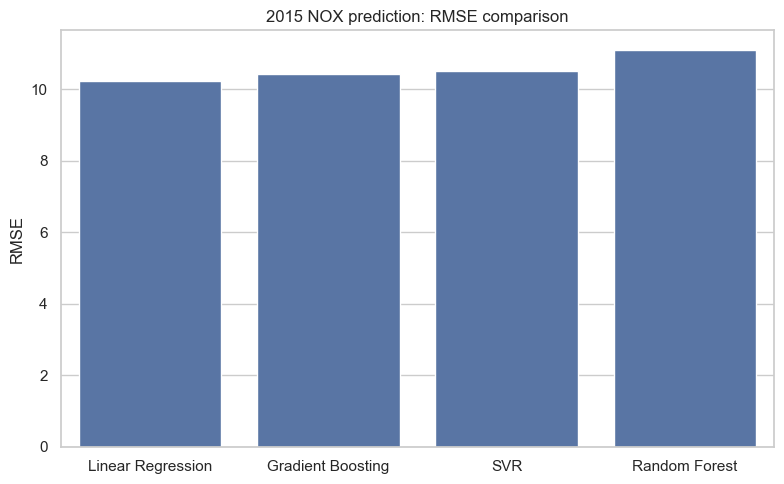

In [27]:
# ============================================================
# PLOT 2015 MODEL COMPARISON
# ============================================================

plt.figure(figsize=(8, 5))
sns.barplot(data=nox_results, x="Model", y="RMSE")
plt.title("2015 NOX prediction: RMSE comparison")
plt.xlabel("")
plt.ylabel("RMSE")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nox_model_comparison_2015.png", dpi=300)
plt.show()


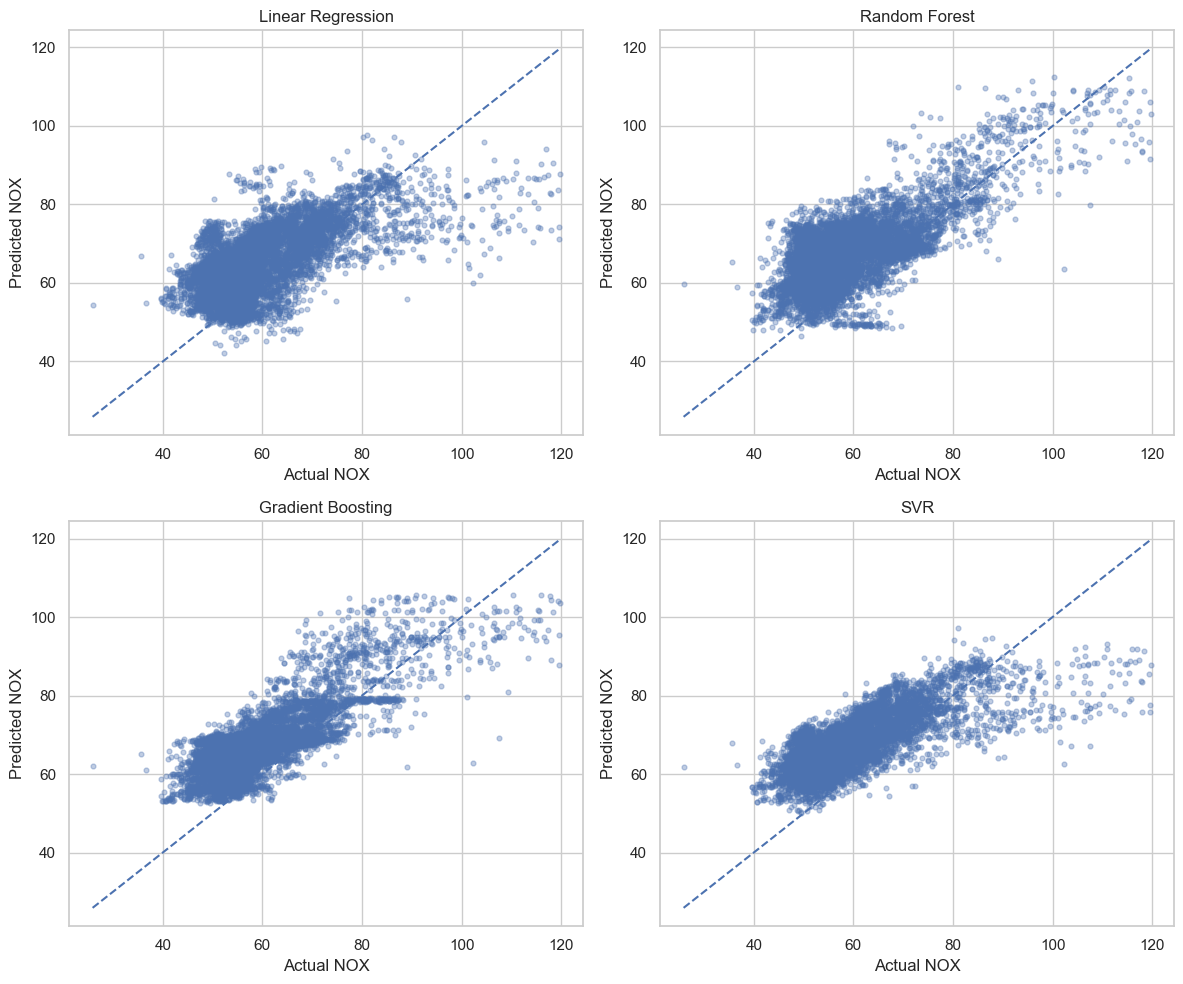

In [28]:
# ============================================================
# PLOT ACTUAL VS PREDICTED NOX
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()
for ax, (model_name, y_pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, y_pred, alpha=0.35, s=12)
    lower = min(y_test.min(), np.min(y_pred))
    upper = max(y_test.max(), np.max(y_pred))
    ax.plot([lower, upper], [lower, upper], linestyle="--")
    ax.set_title(model_name)
    ax.set_xlabel("Actual NOX")
    ax.set_ylabel("Predicted NOX")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nox_actual_vs_predicted_2015.png", dpi=300)
plt.show()


In [29]:
# ============================================================
# EXPORT PREDICTIONS AND MODEL SETTINGS
# ============================================================

prediction_output = test_data[["Year"]].copy()
prediction_output["NOX_actual"] = y_test.to_numpy()
for model_name, y_pred in predictions.items():
    safe_name = model_name.lower().replace(" ", "_")
    prediction_output[f"NOX_{safe_name}"] = y_pred
prediction_output.to_csv(OUTPUT_DIR / "nox_2015_predictions.csv", index=False)
pd.DataFrame([best_svr_params]).to_csv(
    OUTPUT_DIR / "nox_svr_best_parameters.csv", index=False
)
settings = pd.DataFrame([
    {"Item": "Target", "Value": "NOX"},
    {"Item": "Development period", "Value": "2011–2014"},
    {"Item": "Comparison period", "Value": "2015"},
    {"Item": "Validation", "Value": "Chronological holdout: train 2011–2013, validate 2014"},
    {"Item": "SVR tuning sample limit", "Value": MAX_TUNING_SAMPLES},
    {"Item": "Final SVR training sample limit", "Value": MAX_FINAL_SVR_SAMPLES},
    {"Item": "Best SVR parameters", "Value": str(best_svr_params)},
    {"Item": "Best 2014 validation RMSE", "Value": best_validation_rmse}
])
settings.to_csv(OUTPUT_DIR / "nox_svr_settings.csv", index=False)
print("Notebook completed. Results saved to:", OUTPUT_DIR.resolve())


Notebook completed. Results saved to: C:\Users\devra\Music\gas-turbine-ml\outputs\nox_svr
